# Pramana — CPUC QoE experiment runner

This notebook is the **primary experiment runner** for the CPUC broadband-QoE
study. It drives the NetGent / Agentic-Thin-Waist stack on the lab VM to run
**real, measured** network experiments — solo and multi-app concurrent — then
verifies the results are physically correct and saves a structured dataset
(+ plots) ready for the paper.

### Two ways to describe an experiment
- **DIRECT** *(default, deterministic, no LLM)* — you give app names + explicit
  parameters (bandwidth, latency, loss, AQM, CCA, duration). The notebook drives
  the substrate worker directly: `shape → congestion → capture → run`. This is
  the reliable path and is what the sweeps below use.
- **INTENT** *(natural language)* — you write one plain-English sentence and the
  orchestrator (`:8005`) parses + runs it. Requires the orchestration service to
  be running (it is optional in the compose stack and is often stopped).

### Reporting conventions (enforced in code, not left to the analyst)
- **Never a combined throughput plot.** Every run emits **one throughput plot
  per app**, showing only that app's traffic against the cap, with the average
  and peak drawn and annotated. Title format:
  `Throughput — YouTube — 6 Mbps / 50ms / pfifo`.
- **Video apps plot download only.** For YouTube / Twitch / Vimeo / Tubi the
  upload direction is ACKs; adding it to the download makes a 10 Mbps stream
  read as 11–12 Mbps. Upload is still *measured* and stored — just never summed
  into the download.
- **Conferencing apps plot both directions, separately.** For Zoom and Meet both
  directions carry real media, so each gets its own plot.
- **Multi-app runs are split per app.** One capture is taken at the bottleneck
  and then attributed per app (see below). Per-app numbers are written to
  `record.json` under `per_app_stats`.
- **Every run keeps its PCAP.** The capture is saved next to `record.json` and
  the plots — including for runs that fail shaping verification. It is the raw
  evidence and is never discarded.
- **Plots are generated automatically** when a run finishes. There is no
  separate plotting call to remember.

### How a shared capture is split per app
Two mechanisms, in priority order:

1. **Namespace alias IP** — when the substrate worker assigns each app its own
   source IP (`POST /shape/per_app_marks`), every packet carries the app
   identity in its local endpoint. Exact, no heuristics.
2. **Remote endpoint** — the *currently deployed* worker runs every browser app
   in the same namespace (`ns1`, one source IP), so mechanism 1 is unavailable.
   Instead each remote IP is identified from the plaintext **DNS answers and TLS
   SNI inside the same capture**, then mapped to an app by domain suffix
   (`googlevideo.com` → YouTube, `vimeocdn.com` → Vimeo, …). Measured coverage
   on real concurrent captures: **>97% of bytes**.

Traffic belonging to the *browser* rather than any app under test — Chrome's
component updates and optimization-guide model downloads — is bucketed as
`browser_infra` and kept out of every per-app plot. This is not a rounding
detail: on a real 6 Mbps YouTube+Vimeo capture, **84 MB of 113 MB was Chrome
infrastructure**, against 19 MB of YouTube and 7 MB of Vimeo. A combined plot of
that run would have shown roughly four times the real video throughput.

### What each run measures (network side)
Per app, per direction: `avg / peak / p95 throughput`, `total_mb`,
`stall_seconds` (time under 5% of the cap), `delivered_fraction` (share of the
run with active traffic), and a `served` / `starved` classification —
**served** when peak ≥ 30% of the cap (the app really streamed), **starved**
when peak < 30% (it got almost nothing). Link-level stats and the
`shaping_verified` flag are kept separately, under `network_stats`.

### What gets saved (per run, under `results/pramana_runs/<slug>_<id>/`)
| file | contents |
|---|---|
| `capture.pcap` | raw capture at the bottleneck — always saved |
| `throughput_<app>.png` | one per app (per direction for calls) |
| `qoe_summary_<app>.png` | one per app: stalls, delivered fraction, peak vs avg, verdict |
| `record.json` | config + `network_stats` + `per_app_stats` + artifact paths |

Every run is also appended to `results/pramana_runs/dataset_index.jsonl`.

### Honest limitations of the currently deployed stack
- **Player QoE is not available.** The deployed substrate NetGent is the "v2"
  engine, whose actions are `go_to_url / wait / click_element / …` with **no
  `start_stats_logging`** — so resolution / rebuffer rate / dropped frames
  aren't produced. Every record is tagged **`player_qoe_available: false`**, and
  the QoE summary plot says so on its face. The metrics it *does* show are
  network-derived proxies computed from the PCAP. When the team deploys the
  NetGent build with stats logging, that flag flips to `true` and the same plot
  automatically grows a player-side panel.
- Queue-depth (`qtrace`) time series are **not** available (deployed
  `main_local` has no `/qtrace`).
- Latency/loss are applied **link-wide** (netem), not per-flow.

> **Where to run:** run this notebook **on the lab VM** (or with an SSH tunnel to
> ports 8002–8005). See the last cell for exact instructions.


## 0 · Setup & health check

Loads the helper module and probes the four services the notebook depends on.
`DIRECT` mode needs substrate (`:8002`) + telemetry (`:8004`). `INTENT` mode
additionally needs the orchestrator (`:8005`).

If you are **not** running on the VM host, set the service URLs / capture dir to
match your SSH tunnel before running (see the commented lines).

In [1]:
import pramana_helpers as ph
from pramana_helpers import ExperimentConfig, run_experiment, run_sweep

# ── Where the services live ──────────────────────────────────────────────
# Defaults assume this notebook runs ON the lab VM, where the stack is on
# localhost. Everything is environment-driven, so a different host needs env
# vars, not code edits:
#   PRAMANA_SUBSTRATE_URL / _NETGENT_URL / _TELEMETRY_URL / _ORCH_URL
#   PRAMANA_COLLECTOR_IMAGE   (default video-qoe-collector:latest)
#   PRAMANA_SUBSTRATE_CONTAINER, PRAMANA_DOCKER, PRAMANA_RESULTS_DIR
#
# `shared.apps` / `shared.qoe` come from this same repo — nothing to configure.
print(ph.shared_repo_status())
print("results ->", ph.RESULTS_ROOT)

# Correctness knobs.
ph.SHAPING_TOLERANCE = 0.15   # measured avg throughput must be within ±15% of cap
ph.STRICT_SHAPING = True      # raise (don't save trusted data) if shaping fails

ph.stack_health()


shared.apps + shared.qoe loaded from /home/student/sthanav-agentic-thin-waist (9 apps)
results -> /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs
  substrate (:8002)      up
  netgent (:8003)        up
  telemetry (:8004)      up
  orchestrator (:8005)   up


{'substrate (:8002)': 'up',
 'netgent (:8003)': 'up',
 'telemetry (:8004)': 'up',
 'orchestrator (:8005)': 'up'}

## 1 · Choose your experiment — DIRECT or INTENT

Pick **one** path per run. The DIRECT block is active by default; comment it out
and uncomment the INTENT block to use natural language instead.

**Parameters you can set** (all recorded in the dataset):
- **apps**: `youtube`, `twitch`, `vimeo`, `tubi`, `zoom`, `meet`, `wget`
  (one app = solo, several = concurrent on one shared bottleneck)
- **bandwidth_mbps**: 1, 3, 6, 10, 25, 50, 100, 200
- **latency_ms**: 0, 15, 25, 50, 100, 200
- **loss_pct**: 0, 0.1, 0.5, 1, 2, 5
- **aqm**: `pfifo`, `fq_codel`, `codel`
- **cca**: `cubic`, `bbr`, `reno`
- **controller**: `playwright` or `pyautogui` (recorded; deployed browser path is Playwright)
- **duration_s**, **trial**, **buffer_packets**
- **app_urls**: per-app URL overrides — **required** for `zoom` / `meet`
  (a join URL) and recommended for `twitch` (a live channel)


In [2]:
# ═══════════════════════════════════════════════════════════════════════
#  OPTION A — DIRECT (deterministic, no LLM).  ◀ active by default
# ═══════════════════════════════════════════════════════════════════════
EXECUTION_MODE = "direct"
CONTROLLER = "playwright"          # "playwright" | "pyautogui"

cfg = ExperimentConfig(
    apps=["tubi"],              # one app = solo; more = concurrent
    bandwidth_mbps=6,
    latency_ms=50,
    loss_pct=0,
    aqm="pfifo",
    cca="cubic",
    duration_s=60,
    controller=CONTROLLER,
    trial=1,
)

# ═══════════════════════════════════════════════════════════════════════
#  OPTION B — INTENT (natural language, needs orchestrator :8005).
#  Comment out the block above and uncomment these two lines to use it.
# ═══════════════════════════════════════════════════════════════════════
# EXECUTION_MODE = "intent"
# INTENT = ("Run YouTube on a 6 Mbps bottleneck with 50 ms latency for 60 "
#           "seconds using cubic congestion control and a pfifo queue.")

print(f"Mode = {EXECUTION_MODE}")
if EXECUTION_MODE == "direct":
    print("Experiment:", cfg.make_slug())
    for a in cfg.apps:
        print(f"  {a}: plotting {', '.join(ph.app_plot_directions(a))}")


Mode = direct
Experiment: tubi_6mbps_50ms_0pct_pfifo_cubic_solo_t1
  tubi: plotting download


## 2 · Baseline — fast reference set  ·  ~12 min  ·  **runs by default**

The standard scenarios we treat as reference comparisons: a bandwidth ladder at
one representative latency (50 ms), the same tier run solo and concurrently, so
contention is measurable. Five runs at ~2.3 min each.

Run this first — to sanity-check the pipeline, or to get quick reference numbers.
For the full parameter matrix see **§4**, which is opt-in and takes ~45 min.

Every run here goes through exactly the same capture, per-app attribution and
`record.json` path as the full sweep — nothing is shortened for speed except the
number of scenarios. Validate with `validate_runs.py` the same way (see §7).


In [3]:
# ── MISSING 2-APP COMBOS: youtube+tubi and vimeo+tubi ────────────────────
# Same conditions as the existing combo matrix: 50 ms, pfifo, cubic, 0% loss,
# 120 s, across the bandwidth ladder.
import shutil

LADDER   = [3, 6, 10, 50]
COMBOS   = [["youtube", "tubi"], ["vimeo", "tubi"]]
LAT_MS   = 50
DURATION = 120
MIN_FREE_MB = 400          # abort cleanly rather than die mid-capture

baseline_records = []
combo_records    = []
record = None
concurrent_cfg = None
concurrent_record = None
aborted = False

if EXECUTION_MODE == "direct":
    for _apps in COMBOS:
        if aborted: break
        for _bw in LADDER:
            free_mb = shutil.disk_usage("/").free / 1e6
            if free_mb < MIN_FREE_MB:
                print(f"\n!! ABORT: only {free_mb:.0f} MB free (< {MIN_FREE_MB}); "
                      f"stopping before {'+'.join(_apps)} @ {_bw} Mbps", flush=True)
                aborted = True
                break
            print(f"\n===== {'+'.join(_apps)} @ {_bw} Mbps / {LAT_MS} ms / {DURATION}s "
                  f"(free {free_mb:.0f} MB) =====", flush=True)
            concurrent_cfg = ExperimentConfig(
                apps=_apps, bandwidth_mbps=_bw, latency_ms=LAT_MS, loss_pct=0,
                aqm="pfifo", cca="cubic", duration_s=DURATION,
                controller=CONTROLLER, tag="tubi_combos",
            )
            try:
                concurrent_record = run_experiment(concurrent_cfg, mode="direct")
            except Exception as exc:
                print(f"  ! run failed: {type(exc).__name__}: {exc}", flush=True)
                concurrent_record = None
            if concurrent_record:
                combo_records.append(concurrent_record)
                record = concurrent_record
    baseline_records = list(combo_records)
    print(f"\ncombos complete: {len(combo_records)} runs"
          f"{' (ABORTED EARLY - low disk)' if aborted else ''}", flush=True)
else:
    print("this cell requires EXECUTION_MODE == 'direct'")



===== youtube+tubi @ 3 Mbps / 50 ms / 120s (free 1338 MB) =====


▶ DIRECT run: youtube+tubi_3mbps_50ms_0pct_pfifo_cubic_concurrent2_t1
  cap=3Mbps lat=50ms loss=0% aqm=pfifo cca=cubic dur=120s apps=['youtube', 'tubi']
  • shaping ...
  • capture on veth2 (auto-stop 180s) ...


  • real QoE collector for ['youtube', 'tubi'] ...
    · driving 2 browser app(s) in real Chrome inside ns1 (youtube, tubi) ...


      [youtube] summary: 115 samples written to /out/youtube_stats.jsonl | current_time_secs range=[29.429359, 149.25552] | advanced=True | final_resolution=854x480
      [tubi] summary: 115 samples written to /out/tubi_stats.jsonl | current_time_secs range=[33.491642, 153.347428] | advanced=True | final_resolution=854x480
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+tubi_3mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_77d0d9a980/capture.pcap (63.1 MB)


...

    method=remote_hostname  local=['172.16.1.1']  99.0% of bytes attributed
      vimeo                95.41 MB
      tubi                 50.52 MB
      other                 1.54 MB
      browser_infra         1.01 MB
      off_link              0.00 MB
    · vimeo: served (dl avg 5.44 / peak 9.97 Mbps, delivered 88%)
    · tubi: served (dl avg 2.87 / peak 9.85 Mbps, delivered 71%)
  • generating per-app plots ...


    · vimeo (download): throughput + qoe_summary saved [served, avg 5.44 Mbps]


    · tubi (download): throughput + qoe_summary saved [served, avg 2.87 Mbps]


  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/vimeo+tubi_10mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_b44db6d11f
    pcap: capture.pcap | plots: 4 | record.json

!! ABORT: only 144 MB free (< 400); stopping before vimeo+tubi @ 50 Mbps



combos complete: 7 runs (ABORTED EARLY - low disk)


## 3 · Multi-app concurrent run (contention on a shared link)

The baseline in §2 already produced this run — YouTube + Vimeo sharing one
6 Mbps / 50 ms bottleneck — so nothing re-runs here. The cells below inspect it:
per-app plots, the attribution split, and real player-side QoE.


In [4]:
# The concurrent run came from the baseline cell (§2); no second run needed.
# `concurrent_cfg` / `concurrent_record` are already defined there.
assert concurrent_record, "run the baseline cell (§2) first"
print(f"inspecting: {concurrent_record['slug']}  "
      f"({'+'.join(concurrent_cfg.apps)} @ {concurrent_cfg.bandwidth_mbps} Mbps / "
      f"{concurrent_cfg.latency_ms} ms)")


inspecting: vimeo+tubi_10mbps_50ms_0pct_pfifo_cubic_concurrent2_t1  (vimeo+tubi @ 10 Mbps / 50 ms)


Run folder: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/vimeo+tubi_10mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_b44db6d11f

  plot_combined_throughput = False
  per_app_plots            = True
  player_qoe_available     = True
  pcap saved               = True  (/home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/vimeo+tubi_10mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_b44db6d11f/capture.pcap)
  attribution method       = remote_hostname  (99.0% of bytes attributed)

Per-app results:
  vimeo     served    avg 5.443 Mbps  peak 9.972 Mbps  stalls 17.0s  delivered 0.876
  tubi      served    avg 2.873 Mbps  peak 9.854 Mbps  stalls 40.0s  delivered 0.708

Files written:
  capture.pcap
  collector.log
  qoe
  qoe_summary_tubi.png
  qoe_summary_vimeo.png
  record.json
  throughput_tubi.png
  throughput_vimeo.png


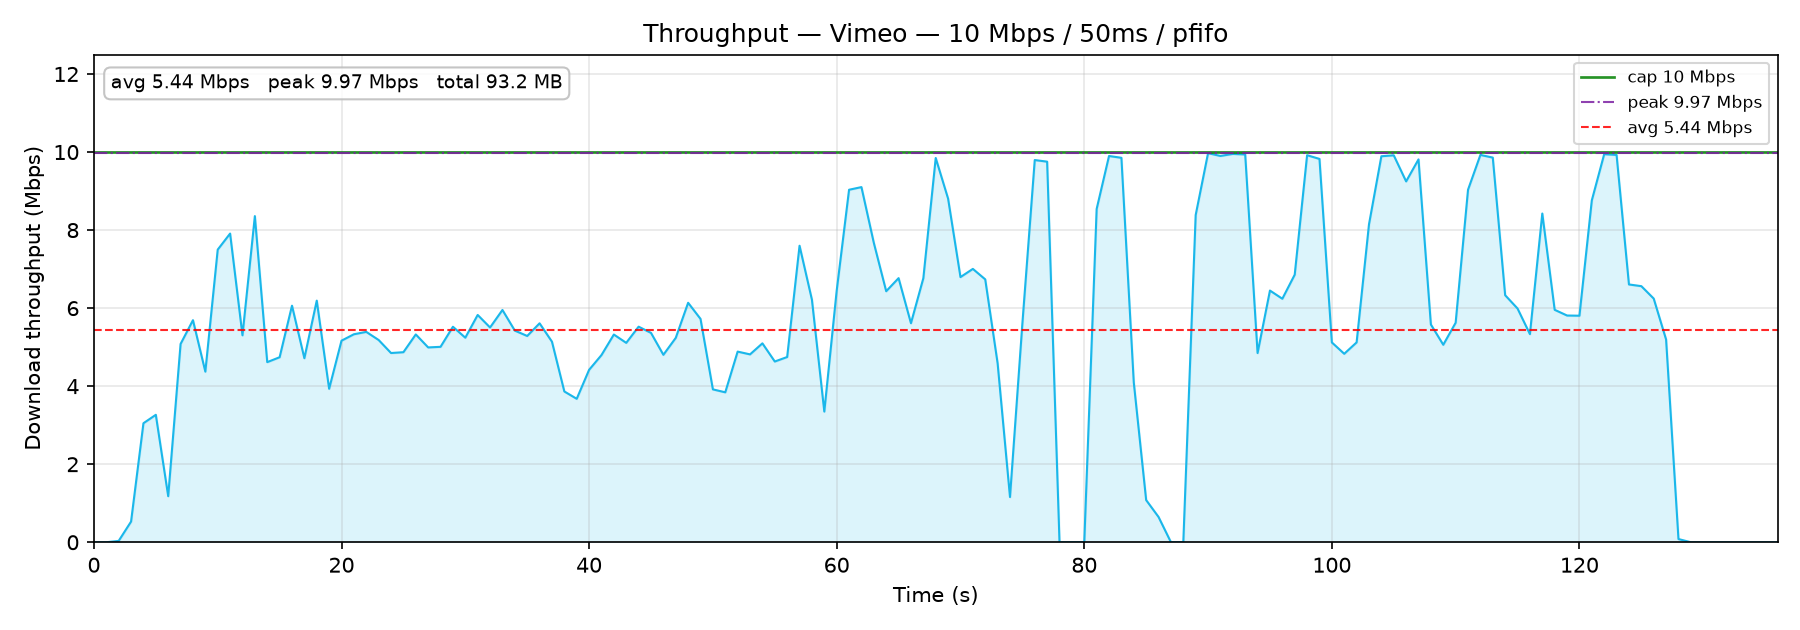

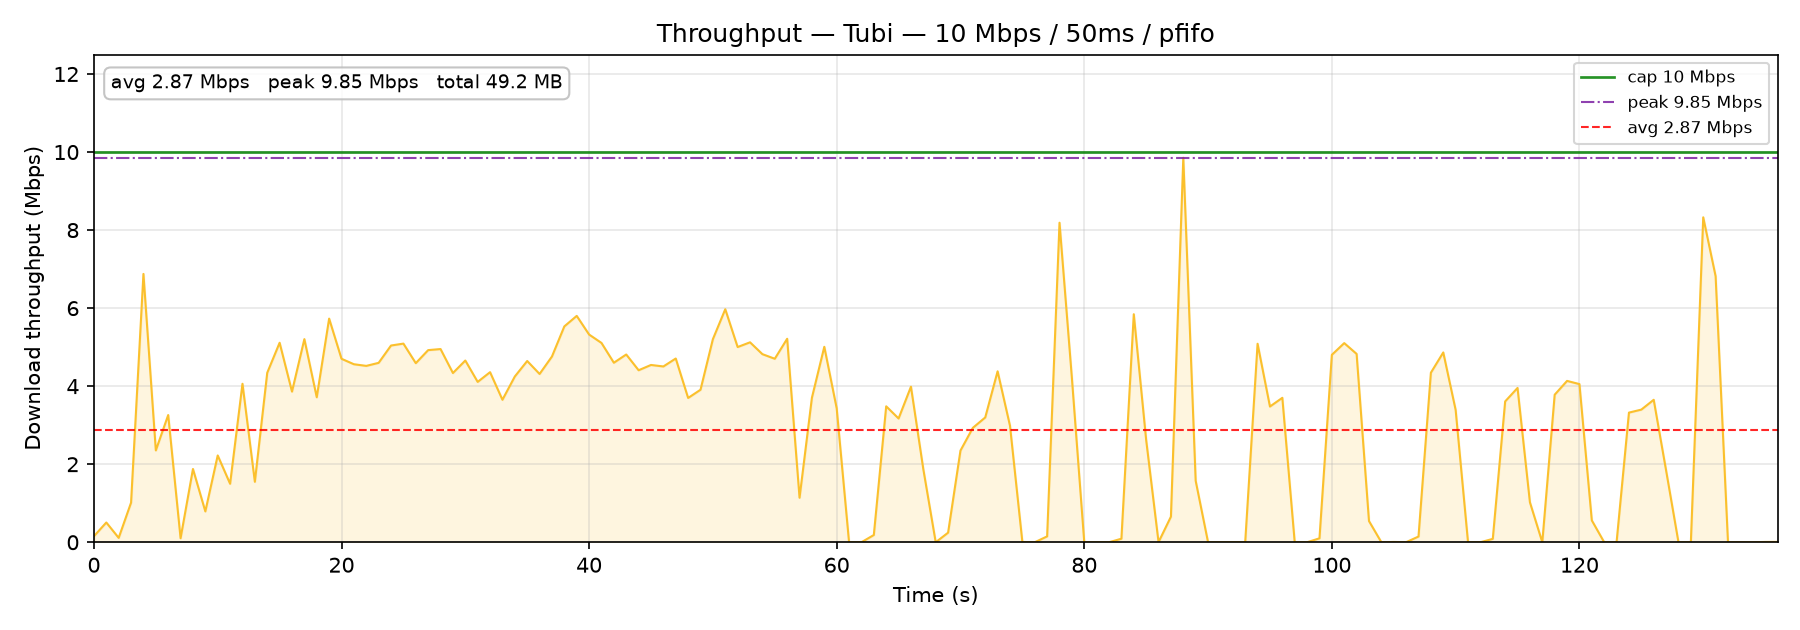

In [5]:
# ── Verify the per-app split: one plot per app, none combined ────────────
from pathlib import Path
from IPython.display import Image, display

run_dir = Path(concurrent_record["artifacts"]["dir"])
print(f"Run folder: {run_dir}\n")

print(f"  plot_combined_throughput = {concurrent_record['plot_combined_throughput']}")
print(f"  per_app_plots            = {concurrent_record['per_app_plots']}")
print(f"  player_qoe_available     = {concurrent_record['player_qoe_available']}")
print(f"  pcap saved               = {concurrent_record['artifacts']['pcap_saved']}"
      f"  ({run_dir / 'capture.pcap'})")
print(f"  attribution method       = "
      f"{concurrent_record['limitations']['per_app_attribution_method']}"
      f"  ({100 * concurrent_record['limitations']['attributed_byte_fraction']:.1f}%"
      f" of bytes attributed)\n")

print("Per-app results:")
for app, st in concurrent_record["per_app_stats"].items():
    dl = st["download"]
    print(f"  {app:9s} {st['classification']:9s} "
          f"avg {dl['avg_throughput_mbps']} Mbps  peak {dl['peak_throughput_mbps']} Mbps  "
          f"stalls {dl['stall_seconds']}s  delivered {dl['delivered_fraction']}")

print("\nFiles written:")
for f in sorted(run_dir.iterdir()):
    print(f"  {f.name}")

# Show each app's throughput plot — separately, never overlaid.
for app in concurrent_cfg.apps:
    png = run_dir / f"throughput_{app}.png"
    if png.exists():
        display(Image(filename=str(png)))


### QoE proxy metrics (no player-side logging required)

The deployed NetGent build has no player stats, so resolution / rebuffer rate /
dropped frames genuinely cannot be measured — every record says so with
`player_qoe_available: false`. What the PCAP *can* honestly support is plotted
in `qoe_summary_<app>.png`:

- **throughput over time** — that app only, download only for video
- **stall time** — shaded spans where throughput fell below 5% of the cap
- **delivered fraction** — % of the run that had active traffic, annotated
- **peak vs average** — two horizontal reference lines
- **traffic classification** — `served` (peak ≥ 30% of cap) or `starved`

> Note: the capture starts before the browser has finished warming up, so the
> pre-playback period counts toward `stall_seconds` and against
> `delivered_fraction`. Read them relative to each other across runs at the same
> duration rather than as absolute player rebuffering.

When the stats-logging NetGent build is deployed, flip `player_qoe_available`
to `true` and pass the player series to `generate_run_plots(..., player_qoe=...)`
— the same figure grows a second panel with the real player-side metrics.


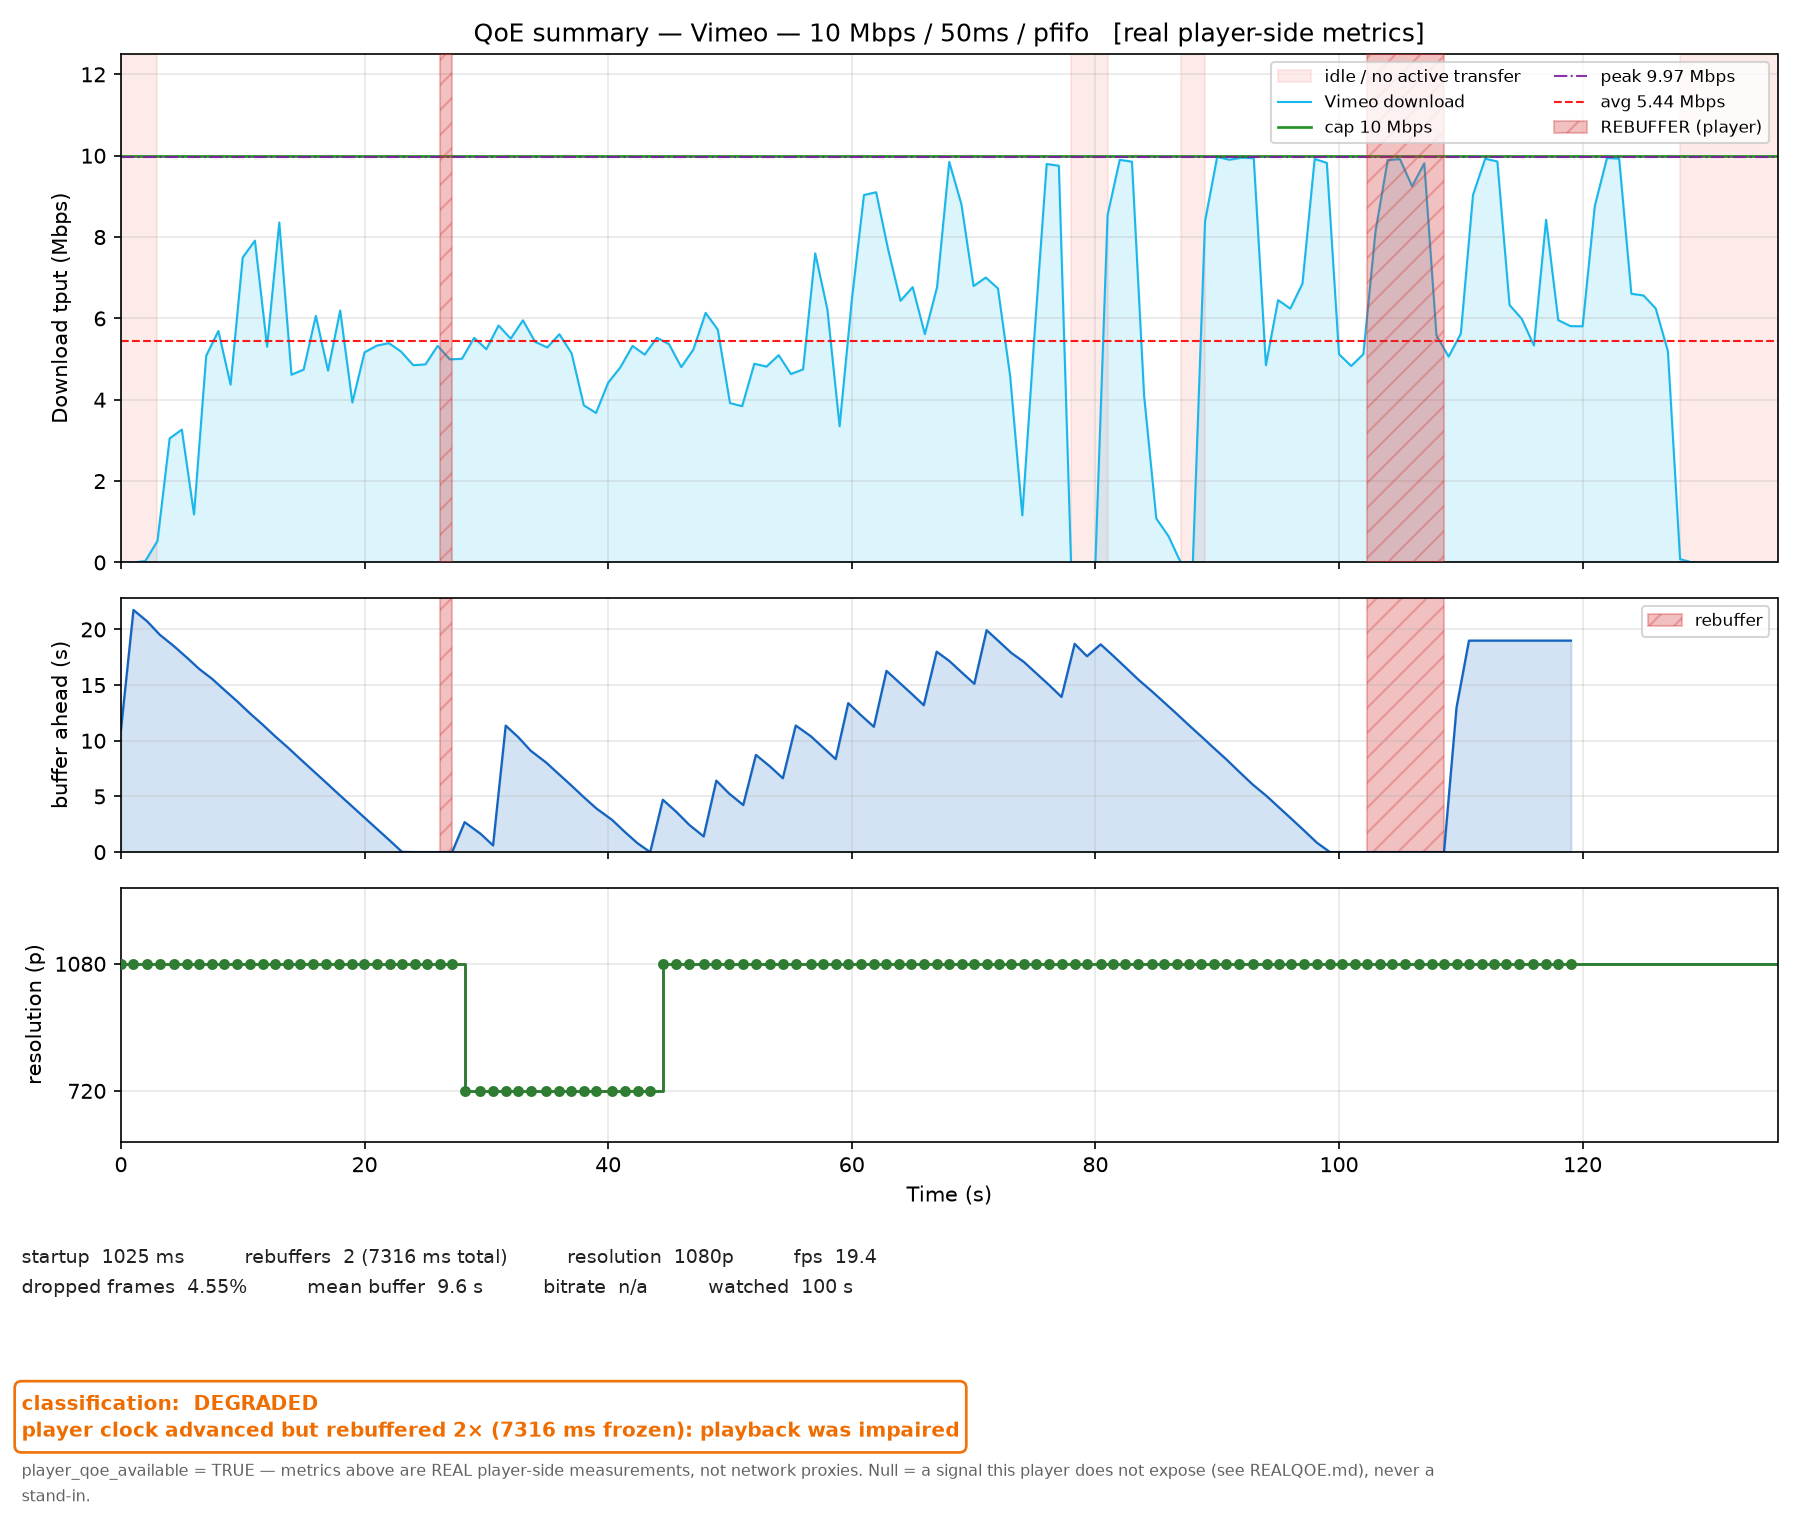

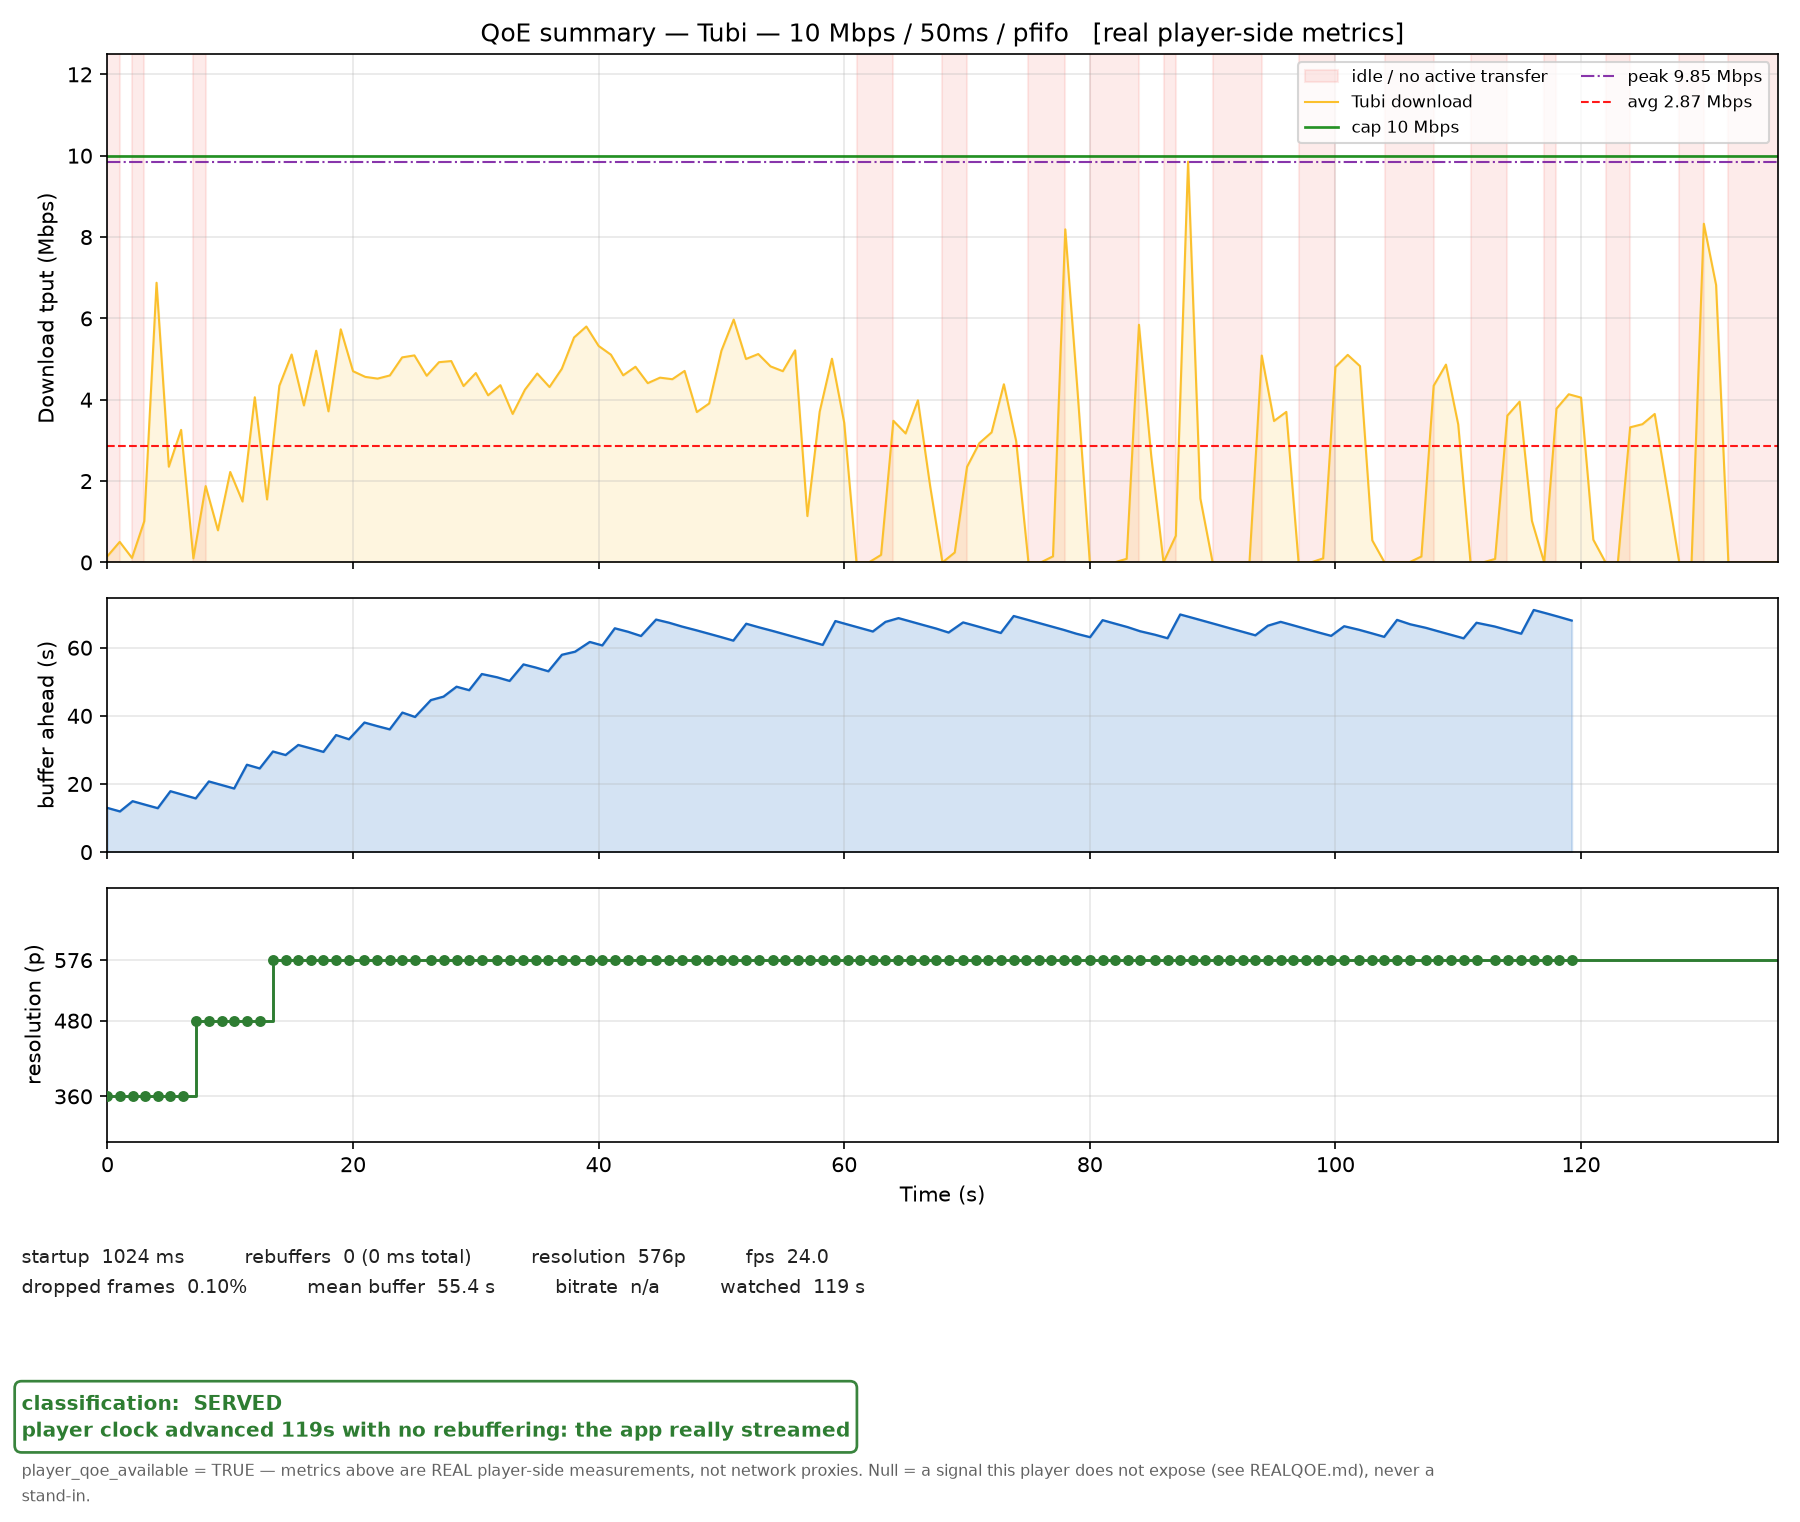

In [6]:
# Per-app QoE summaries from the run above.
for app in concurrent_cfg.apps:
    png = run_dir / f"qoe_summary_{app}.png"
    if png.exists():
        display(Image(filename=str(png)))


### Real player-side QoE

Every browser app in the run is driven in **real headed Chrome** (Xvfb +
SeleniumBase/undetected-chromedriver), launched *inside the substrate worker's
shaped `ns1` namespace* so its traffic is genuinely rate-limited and captured.
Per-second player samples are reduced by `shared/qoe.py` into the `QoEMetrics`
fields defined in `shared/models/README.md`.

`n/a` in the table below means the player genuinely does not expose that signal
for that app — see `REALQOE.md` for the per-app matrix. It is never a
placeholder. In particular **bitrate stays null unless it is truly byte-derived**:
YouTube's `bandwidth_kbps` is a connection-speed estimate, not the media bitrate,
and is reported separately as `connection_speed_estimate_mbps`.

Apps that need a remote video peer (Meet, Zoom) are marked `skipped` with a
reason rather than measured against their own local camera preview, and the rest
of the run still succeeds.

In [7]:
# Real per-app QoE for the most recent run (no browser code here — the
# collector runs on the VM; this is just the client view).
ph.show_player_qoe(concurrent_record)

Real player-side QoE — player_qoe_available = True
  source: real Chrome driven inside the shaped ns1 namespace; metrics per shared/models/README.md QoEMetrics



,app,status,resolution,startup,rebuffers,rebuf_time,dropped,fps,bitrate,buffer,watched
0,vimeo,ok,1080p,1025 ms,2,7316 ms,4.55%,19.4,n/a,9.6 s,100 s
1,tubi,ok,576p,1024 ms,0,0 ms,0.1%,24,n/a,55.4 s,119 s


,app,status,resolution,startup,rebuffers,rebuf_time,dropped,fps,bitrate,buffer,watched
0,vimeo,ok,1080p,1025 ms,2,7316 ms,4.55%,19.4,n/a,9.6 s,100 s
1,tubi,ok,576p,1024 ms,0,0 ms,0.1%,24,n/a,55.4 s,119 s


## 4 · Full parameter sweep — **OPTIONAL** · ~45 min · does NOT run by default

The broad matrix: bandwidth x latency x loss x AQM x contention, plus the
household tiers (50 / 100 Mbps) and the equity pair. 19 runs at ~2.3 min each.

This is deliberately gated. §2 gives reference numbers in ~12 minutes; run this
only when you want the complete parameter space — for a paper figure, or after a
change that could plausibly move results across the whole matrix.

**To run it:** set `RUN_FULL_SWEEP = True` in the next cell, then execute §4.
Everything it produces goes through the same capture / attribution / `record.json`
path as the baseline, and is validated identically (§5).


In [8]:
# Opt-in switch for §4. Left False so "Run All" stays fast (~12 min, §2 only).
RUN_FULL_SWEEP = True            # <- set True to run the full ~45 min matrix

from pathlib import Path
cmp_dir = ph.RESULTS_ROOT / "comparisons"   # shared by the sweep cells below
print("full sweep ENABLED (~45 min)" if RUN_FULL_SWEEP
      else "full sweep disabled — baseline (§2) is the fast path")


full sweep ENABLED (~45 min)


### 4.1 · AQM comparison — pfifo vs fq_codel (same everything else)


In [9]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    from pathlib import Path

    AQM_APPS = ["youtube", "vimeo"]
    aqm_records = {}
    for aqm in ["pfifo", "fq_codel"]:
        cfg_aqm = ExperimentConfig(
            apps=AQM_APPS, bandwidth_mbps=6, latency_ms=50,
            aqm=aqm, cca="cubic", duration_s=60, controller=CONTROLLER, tag="aqm_cmp",
        )
        aqm_records[aqm] = [run_experiment(cfg_aqm, mode="direct")]

    cmp_dir = ph.RESULTS_ROOT / "comparisons"

    # Per app — this is the fairness comparison that matters.
    for app in AQM_APPS:
        ph.plot_aqm_comparison(
            aqm_records, cmp_dir / f"aqm_pfifo_vs_fqcodel_throughput_{app}.png",
            metric="avg_throughput_mbps", app=app)
        ph.plot_aqm_comparison(
            aqm_records, cmp_dir / f"aqm_pfifo_vs_fqcodel_delivered_{app}.png",
            metric="delivered_fraction", app=app)


▶ DIRECT run: youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_concurrent2_t1
  cap=6Mbps lat=50ms loss=0.0% aqm=pfifo cca=cubic dur=60s apps=['youtube', 'vimeo']
  • shaping ...
  • capture on veth2 (auto-stop 120s) ...


  • real QoE collector for ['youtube', 'vimeo'] ...
    · driving 2 browser app(s) in real Chrome inside ns1 (youtube, vimeo) ...


      [vimeo] summary: 58 samples written to /out/vimeo_stats.jsonl | current_time_secs range=[14.997555, 74.772548] | advanced=True | final_resolution=960x720
      [youtube] summary: 56 samples written to /out/youtube_stats.jsonl | current_time_secs range=[10.327688, 69.336371] | advanced=True | final_resolution=854x480
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_concurrent2_t1_eaf47233c7/capture.pcap (54.4 MB)
  • shaping check: avg 4.90 / cap 6 Mbps (-18.3%) → OK
  • splitting capture per app ...


    method=remote_hostname  local=['172.16.1.1']  72.6% of bytes attributed
      vimeo                 5.66 MB
      youtube               5.55 MB
      other                 4.55 MB
      browser_infra         0.82 MB
    · youtube: served (dl avg 1.65 / peak 3.63 Mbps, delivered 62%)
    · vimeo: served (dl avg 1.65 / peak 3.52 Mbps, delivered 77%)
  • generating per-app plots ...


...

  • shaping check: avg 5.24 / cap 6 Mbps (-12.7%) → OK
  • splitting capture per app ...
    method=remote_hostname  local=['172.16.1.1']  90.3% of bytes attributed
      youtube               4.43 MB
      vimeo                 1.84 MB
      other                 0.75 MB
      browser_infra         0.72 MB
    · youtube: failed_to_deliver (dl avg 3.07 / peak 4.58 Mbps, delivered 100%)
    · vimeo: failed_to_deliver (dl avg 1.22 / peak 2.89 Mbps, delivered 64%)
  • generating per-app plots ...


    · youtube (download): throughput + qoe_summary saved [served, avg 3.07 Mbps]


    · vimeo (download): throughput + qoe_summary saved [served, avg 1.22 Mbps]
  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo_6mbps_50ms_0pct_fq_codel_cubic_concurrent2_t1_68ad6a3dce
    pcap: capture.pcap | plots: 4 | record.json


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/aqm_pfifo_vs_fqcodel_throughput_youtube.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/aqm_pfifo_vs_fqcodel_delivered_youtube.png


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/aqm_pfifo_vs_fqcodel_throughput_vimeo.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/aqm_pfifo_vs_fqcodel_delivered_vimeo.png


### 4.2 · Parameter sweeps — bandwidth, latency, contention


In [10]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs BANDWIDTH (find the cliff) ────────────────────────────────────
    base = ExperimentConfig(apps=["youtube"], latency_ms=0, aqm="pfifo",
                            cca="cubic", duration_s=60, controller=CONTROLLER,
                            tag="sweep_bw")

    bw_records = run_sweep(base, "bandwidth_mbps", [1, 3, 6, 10, 25], mode="direct")

    cmp_dir = ph.RESULTS_ROOT / "comparisons"
    # How much each tier actually delivers to the app, and how close to the cap.
    ph.plot_throughput_vs_bandwidth(bw_records, cmp_dir / "throughput_vs_bw.png",
                                    app="youtube")
    ph.plot_qoe_vs_bandwidth(bw_records, cmp_dir / "delivered_vs_bw.png",
                             metric="delivered_fraction", app="youtube")
    ph.plot_qoe_vs_bandwidth(bw_records, cmp_dir / "peak_vs_bw.png",
                             metric="peak_throughput_mbps", app="youtube")


═══ SWEEP over bandwidth_mbps: [1, 3, 6, 10, 25] ═══

[1/5] bandwidth_mbps=1
▶ DIRECT run: youtube_1mbps_0ms_0pct_pfifo_cubic_solo_t1
  cap=1Mbps lat=0ms loss=0.0% aqm=pfifo cca=cubic dur=60s apps=['youtube']
  • shaping ...


  • capture on veth2 (auto-stop 105s) ...


  • real QoE collector for ['youtube'] ...
    · driving 1 browser app(s) in real Chrome inside ns1 (youtube) ...


      [youtube] summary: 59 samples written to /out/youtube_stats.jsonl | current_time_secs range=[18.523548, 78.102866] | advanced=True | final_resolution=640x360
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_1mbps_0ms_0pct_pfifo_cubic_solo_t1_c5f47b5bb3/capture.pcap (12.9 MB)
  • shaping check: avg 0.93 / cap 1 Mbps (-7.1%) → OK
  • splitting capture per app ...


...

  • shaping check: avg 1.51 / cap 25 Mbps (-94.0%) → OK
  • splitting capture per app ...


    method=remote_hostname  local=['172.16.1.1']  90.0% of bytes attributed
      youtube              12.20 MB
      other                 1.43 MB
      browser_infra         0.65 MB
    · youtube: served (dl avg 1.40 / peak 18.55 Mbps, delivered 28%)
  • generating per-app plots ...


    · youtube (download): throughput + qoe_summary saved [served, avg 1.40 Mbps]
  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_25mbps_0ms_0pct_pfifo_cubic_solo_t1_4d7b945e67
    pcap: capture.pcap | plots: 2 | record.json


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/throughput_vs_bw.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/delivered_vs_bw.png


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/peak_vs_bw.png


In [11]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs LATENCY (does RTT hurt more than bandwidth?) ──────────────────
    base_lat = ExperimentConfig(apps=["youtube"], bandwidth_mbps=10, aqm="pfifo",
                                cca="cubic", duration_s=60, controller=CONTROLLER,
                                tag="sweep_lat")

    lat_records = run_sweep(base_lat, "latency_ms", [0, 25, 50, 100, 200], mode="direct")

    ph.plot_qoe_vs_latency(lat_records, cmp_dir / "throughput_vs_latency.png",
                           metric="avg_throughput_mbps", app="youtube")
    ph.plot_qoe_vs_latency(lat_records, cmp_dir / "stalls_vs_latency.png",
                           metric="stall_seconds", app="youtube")


═══ SWEEP over latency_ms: [0, 25, 50, 100, 200] ═══

[1/5] latency_ms=0
▶ DIRECT run: youtube_10mbps_0ms_0pct_pfifo_cubic_solo_t1
  cap=10Mbps lat=0ms loss=0.0% aqm=pfifo cca=cubic dur=60s apps=['youtube']
  • shaping ...


  • capture on veth2 (auto-stop 105s) ...


  • real QoE collector for ['youtube'] ...
    · driving 1 browser app(s) in real Chrome inside ns1 (youtube) ...


      [youtube] summary: 58 samples written to /out/youtube_stats.jsonl | current_time_secs range=[6.360163, 65.456737] | advanced=True | final_resolution=854x480
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_10mbps_0ms_0pct_pfifo_cubic_solo_t1_d04afb52cc/capture.pcap (17.9 MB)


...

      [youtube] summary: 59 samples written to /out/youtube_stats.jsonl | current_time_secs range=[6.508572, 66.473746] | advanced=True | final_resolution=854x480
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_10mbps_200ms_0pct_pfifo_cubic_solo_t1_d0312f66f2/capture.pcap (18.6 MB)
  • shaping check: avg 1.85 / cap 10 Mbps (-81.5%) → OK
  • splitting capture per app ...


    method=remote_hostname  local=['172.16.1.1']  92.0% of bytes attributed
      youtube              15.84 MB
      other                 1.43 MB
      browser_infra         0.74 MB
      off_link              0.00 MB
    · youtube: served (dl avg 1.63 / peak 9.68 Mbps, delivered 38%)
  • generating per-app plots ...


    · youtube (download): throughput + qoe_summary saved [served, avg 1.63 Mbps]
  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_10mbps_200ms_0pct_pfifo_cubic_solo_t1_d0312f66f2
    pcap: capture.pcap | plots: 2 | record.json


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/throughput_vs_latency.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/stalls_vs_latency.png


In [12]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    # ── QoE vs CONCURRENCY (who gets starved first: 1 vs 2 vs 3 apps) ─────────
    conc_sets = [["youtube"], ["youtube", "vimeo"], ["youtube", "vimeo", "twitch"]]
    conc_records = []
    for apps in conc_sets:
        cfg_c = ExperimentConfig(apps=apps, bandwidth_mbps=6, latency_ms=50,
                                 aqm="pfifo", cca="cubic", duration_s=60,
                                 controller=CONTROLLER, tag="sweep_conc")
        rec = run_experiment(cfg_c, mode="direct")
        if rec:
            conc_records.append(rec)

    # YouTube is in every set, so its curve shows what contention costs *one* app.
    ph.plot_qoe_vs_concurrency(conc_records, cmp_dir / "throughput_vs_concurrency.png",
                               metric="avg_throughput_mbps", app="youtube")
    ph.plot_qoe_vs_concurrency(conc_records, cmp_dir / "delivered_vs_concurrency.png",
                               metric="delivered_fraction", app="youtube")


▶ DIRECT run: youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1
  cap=6Mbps lat=50ms loss=0.0% aqm=pfifo cca=cubic dur=60s apps=['youtube']
  • shaping ...


  • capture on veth2 (auto-stop 105s) ...


  • real QoE collector for ['youtube'] ...
    · driving 1 browser app(s) in real Chrome inside ns1 (youtube) ...


      [youtube] collector failed: OSError: [Errno 28] No space left on device
    ! collector exited 1 (see /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1_cb79449f6f/collector.log)
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1_cb79449f6f/capture.pcap (9.3 MB)


...

    · youtube (download): throughput + qoe_summary saved [served, avg 2.71 Mbps]


    · vimeo (download): throughput + qoe_summary saved [served, avg 0.91 Mbps]


    · twitch (download): throughput + qoe_summary saved [served, avg 1.48 Mbps]
  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo+twitch_6mbps_50ms_0pct_pfifo_cubic_concurrent3_t1_c7d5f9e8b4
    pcap: capture.pcap | plots: 6 | record.json


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/throughput_vs_concurrency.png


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/delivered_vs_concurrency.png


### 4.3 · Equity comparison — well-served vs redlined household


In [13]:
if not RUN_FULL_SWEEP:
    print('skipped — set RUN_FULL_SWEEP = True in the cell above to run this')
else:
    HOUSEHOLD = ["youtube", "vimeo"]   # same apps + size for both profiles

    well_served = run_experiment(ExperimentConfig(
        apps=HOUSEHOLD, bandwidth_mbps=100, latency_ms=10, aqm="fq_codel",
        cca="cubic", duration_s=60, controller=CONTROLLER, tag="equity_well"),
        mode="direct")

    redlined = run_experiment(ExperimentConfig(
        apps=HOUSEHOLD, bandwidth_mbps=3, latency_ms=100, aqm="pfifo",
        cca="cubic", duration_s=60, controller=CONTROLLER, tag="equity_redlined"),
        mode="direct")

    # Headline equity plot, drawn per app so the gap is attributable.
    for app in HOUSEHOLD:
        ph.plot_equity_comparison(well_served, redlined,
                                  cmp_dir / f"equity_throughput_{app}.png",
                                  metric="avg_throughput_mbps", app=app)
        ph.plot_equity_comparison(well_served, redlined,
                                  cmp_dir / f"equity_delivered_{app}.png",
                                  metric="delivered_fraction", app=app)


▶ DIRECT run: youtube+vimeo_100mbps_10ms_0pct_fq_codel_cubic_concurrent2_t1
  cap=100Mbps lat=10ms loss=0.0% aqm=fq_codel cca=cubic dur=60s apps=['youtube', 'vimeo']
  • shaping ...
  • capture on veth2 (auto-stop 120s) ...


  • real QoE collector for ['youtube', 'vimeo'] ...
    · driving 2 browser app(s) in real Chrome inside ns1 (youtube, vimeo) ...


      [vimeo] summary: 57 samples written to /out/vimeo_stats.jsonl | current_time_secs range=[8.068235, 67.741872] | advanced=True | final_resolution=1440x1080
      [youtube] summary: 57 samples written to /out/youtube_stats.jsonl | current_time_secs range=[6.207436, 65.409751] | advanced=True | final_resolution=854x480
      _XSERVTransSocketUNIXCreateListener: mkdir(/tmp/.X11-unix) failed, errno = 17
      _XSERVTransMakeAllCOTSServerListeners: failed to create listener for unix
  • finalising capture + downloading pcap ...


  • pcap saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo_100mbps_10ms_0pct_fq_codel_cubic_concurrent2_t1_617fd435aa/capture.pcap (62.0 MB)


  • shaping check: avg 11.62 / cap 100 Mbps (-88.4%) → OK
  • splitting capture per app ...


...

    method=remote_hostname  local=['172.16.1.1']  94.8% of bytes attributed
      youtube               7.43 MB
      vimeo                 4.06 MB
      browser_infra         1.00 MB
      other                 0.69 MB
    · youtube: served (dl avg 1.55 / peak 2.94 Mbps, delivered 95%)
    · vimeo: served (dl avg 0.83 / peak 2.39 Mbps, delivered 76%)
  • generating per-app plots ...


    · youtube (download): throughput + qoe_summary saved [served, avg 1.55 Mbps]


    · vimeo (download): throughput + qoe_summary saved [served, avg 0.83 Mbps]
  ✓ saved → /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/youtube+vimeo_3mbps_100ms_0pct_pfifo_cubic_concurrent2_t1_fbac54a524
    pcap: capture.pcap | plots: 4 | record.json


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/equity_throughput_youtube.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/equity_delivered_youtube.png


Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/equity_throughput_vimeo.png
Saved: /home/student/sthanav-agentic-thin-waist/experiments/pramana/results/pramana_runs/comparisons/equity_delivered_vimeo.png


## 5 · Dataset & history

`load_dataset()` flattens every DIRECT run from
`results/pramana_runs/dataset_index.jsonl` into **one row per app per run**,
carrying that app's own throughput in its plotted direction plus its
`served` / `starved` classification. The combined link total is deliberately not
a column — it is not a per-app measurement.

`show_history()` lists the most recent rows the telemetry service has stored.


In [14]:
from IPython.display import display

df = ph.load_dataset()          # one row per app per run
if df is not None:
    display(df)

ph.show_history(limit=15)       # recent rows from the telemetry service

# Bring an older run folder up to the per-app convention (re-splits its pcap and
# rewrites its record.json + plots — no re-run needed):
# ph.replot_run("results/pramana_runs/<slug>_<id>")


,slug,apps,concurrency,bandwidth_mbps,latency_ms,loss_pct,aqm,cca,shaping_verified,workflow_ok,...,fps,bitrate_mbps,avg_throughput_mbps,peak_throughput_mbps,p95_throughput_mbps,total_mb,stall_seconds,delivered_fraction,classification,attribution
0,youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1,youtube,solo,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.97,None,1.595,5.897,5.565,14.953,23.0,0.693,served,remote_hostname
1,youtube_6mbps_50ms_0pct_pfifo_cubic_solo_t1,youtube,solo,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.53,None,1.623,5.832,5.583,14.813,22.0,0.699,served,remote_hostname
2,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.99,None,1.535,4.788,4.208,18.418,7.0,0.927,served,remote_hostname
3,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,23.85,None,1.254,2.568,2.281,15.043,7.0,0.927,served,remote_hostname
4,youtube+vimeo_6mbps_50ms_0pct_pfifo_cubic_conc...,youtube+vimeo,concurrent2,6.0,50.0,0.0,pfifo,cubic,True,True,...,24.99,None,0.453,5.713,3.845,5.384,82.0,0.137,served,remote_hostname
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,youtube+vimeo+twitch_6mbps_50ms_0pct_pfifo_cub...,youtube+vimeo+twitch,concurrent3,6.0,50.0,0.0,pfifo,cubic,True,False,...,27.93,None,1.477,4.206,3.848,4.984,9.0,0.667,served,remote_hostname
370,youtube+vimeo_100mbps_10ms_0pct_fq_codel_cubic...,youtube+vimeo,concurrent2,100.0,10.0,0.0,fq_codel,cubic,True,True,...,25.00,None,3.444,28.553,28.553,8.180,15.0,0.211,served,remote_hostname
371,youtube+vimeo_100mbps_10ms_0pct_fq_codel_cubic...,youtube+vimeo,concurrent2,100.0,10.0,0.0,fq_codel,cubic,True,True,...,23.97,None,7.182,55.520,55.520,17.056,16.0,0.158,served,remote_hostname
372,youtube+vimeo_3mbps_100ms_0pct_pfifo_cubic_con...,youtube+vimeo,concurrent2,3.0,100.0,0.0,pfifo,cubic,True,True,...,24.98,None,1.553,2.936,2.930,7.182,2.0,0.946,served,remote_hostname


15 most recent experiment(s) in telemetry:


,when,app,status,capacity (Mbps),latency (ms),throughput (Mbps)
0,2026-09-13 20:58:21,exp-fbac54a524,success,3,100,0.827
1,2026-09-13 20:58:21,exp-fbac54a524,success,3,100,1.553
2,2026-09-13 20:55:40,exp-617fd435aa,success,100,10,7.182
3,2026-09-13 20:55:39,exp-617fd435aa,success,100,10,3.444
4,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,1.477
5,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,0.91
6,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,2.712
7,2026-09-13 20:50:33,exp-15f7c1ecc0,success,6,50,1.417
8,2026-09-13 20:50:33,exp-15f7c1ecc0,success,6,50,2.984
9,2026-09-13 20:48:39,exp-cb79449f6f,success,6,50,3.882


,when,app,status,capacity (Mbps),latency (ms),throughput (Mbps)
0,2026-09-13 20:58:21,exp-fbac54a524,success,3,100,0.827
1,2026-09-13 20:58:21,exp-fbac54a524,success,3,100,1.553
2,2026-09-13 20:55:40,exp-617fd435aa,success,100,10,7.182
3,2026-09-13 20:55:39,exp-617fd435aa,success,100,10,3.444
4,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,1.477
5,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,0.91
6,2026-09-13 20:53:30,exp-c7d5f9e8b4,success,6,50,2.712
7,2026-09-13 20:50:33,exp-15f7c1ecc0,success,6,50,1.417
8,2026-09-13 20:50:33,exp-15f7c1ecc0,success,6,50,2.984
9,2026-09-13 20:48:39,exp-cb79449f6f,success,6,50,3.882


## How to run this on the lab VM

Full setup, including building the collector image, is in
[`experiments/pramana/README.md`](README.md). Short version:

### Option A — run Jupyter on the VM (recommended)
```bash
# 1) SSH in
ssh -p 2204 student@128.111.5.230

# 2) clone this repo and bring the stack up
git clone https://github.com/sthanavm/agentic-thin-waist.git
cd agentic-thin-waist
cp .env.example .env
docker compose up -d postgres telemetry-service substrate-worker
#    DIRECT mode needs substrate-worker(:8002) + telemetry-service(:8004).

# 3) build the real-Chrome QoE collector (once, ~2 GB)
docker build -t video-qoe-collector:latest \
  services/orchestration/scripts/selenium_video_qoe/

# 4) deps + Jupyter, then launch bound to localhost
pip install -r experiments/pramana/requirements.txt
jupyter notebook --no-browser --port 8888
```
Then tunnel the Jupyter port from your laptop and open the printed URL:
```bash
ssh -p 2204 -L 8888:localhost:8888 student@128.111.5.230
```
Open `experiments/pramana/pramana_demo.ipynb`.

**Which cells to run**

| | what | time |
|---|---|---|
| §2 Baseline | fixed reference scenarios; runs on *Run All* | ~12 min |
| §4 Full sweep | whole parameter matrix; opt-in via `RUN_FULL_SWEEP = True` | ~45 min |

*Run All* executes §2 only. §4 stays skipped until you flip the switch, so opening the notebook never commits you to the long matrix.

### Option B — notebook on your laptop, services tunnelled
```bash
ssh -p 2204 student@128.111.5.230 \
  -L 8002:localhost:8002 -L 8004:localhost:8004
```
The stack is driven over HTTP and the pcap is downloaded over HTTP, so the
network side works. **Player QoE does not** — the collector is launched with
`docker run` on the machine running this notebook, and it must join the substrate
worker's `ns1` namespace, which only exists on the VM. Use Option A for real QoE.

### Non-interactive runs (long sweeps)
```bash
tmux new -s pramana
papermill experiments/pramana/pramana_demo.ipynb out.ipynb \
  -p RUN_FULL_SWEEP true      # omit to run the ~12 min baseline only
```

Results land under `experiments/pramana/results/pramana_runs/` (gitignored) —
one folder per run with `capture.pcap`, `record.json`, `qoe/<app>_stats.jsonl`,
and per-app `throughput_<app>.png` + `qoe_summary_<app>.png`.
